In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv('/content/bank-full.csv', sep=';')

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   age           job  marital  education default  balance housing loan  \
0   58    management  married   tertiary      no     2143     yes   no   
1   44    technician   single  secondary      no       29     yes   no   
2   33  entrepreneur  married  secondary      no        2     yes  yes   
3   47   blue-collar  married    unknown      no     1506     yes   no   
4   33       unknown   single    unknown      no        1      no   no   

   contact  day month  duration  campaign  pdays  previous poutcome   y  
0  unknown    5   may       261         1     -1         0  unknown  no  
1  unknown    5   may       151         1     -1         0  unknown  no  
2  unknown    5   may        76         1     -1         0  unknown  no  
3  unknown    5   may        92         1     -1         0  unknown  no  
4  unknown    5   may       198         1     -1         0  unknown  no  


In [5]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset information:")
df.info()

Dataset shape: (45211, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  in

In [6]:
print("Missing values in each column:")

print(df.isnull().sum())

print("\nTotal missing values:")

print(df.isnull().sum().sum())

Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Total missing values:
0


In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [8]:
# Display statistical information about numerical columns
print(df.describe())

                age        balance           day      duration      campaign  \
count  45211.000000   45211.000000  45211.000000  45211.000000  45211.000000   
mean      40.936210    1362.272058     15.806419    258.163080      2.763841   
std       10.618762    3044.765829      8.322476    257.527812      3.098021   
min       18.000000   -8019.000000      1.000000      0.000000      1.000000   
25%       33.000000      72.000000      8.000000    103.000000      1.000000   
50%       39.000000     448.000000     16.000000    180.000000      2.000000   
75%       48.000000    1428.000000     21.000000    319.000000      3.000000   
max       95.000000  102127.000000     31.000000   4918.000000     63.000000   

              pdays      previous  
count  45211.000000  45211.000000  
mean      40.197828      0.580323  
std      100.128746      2.303441  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%       -1.000000      0.

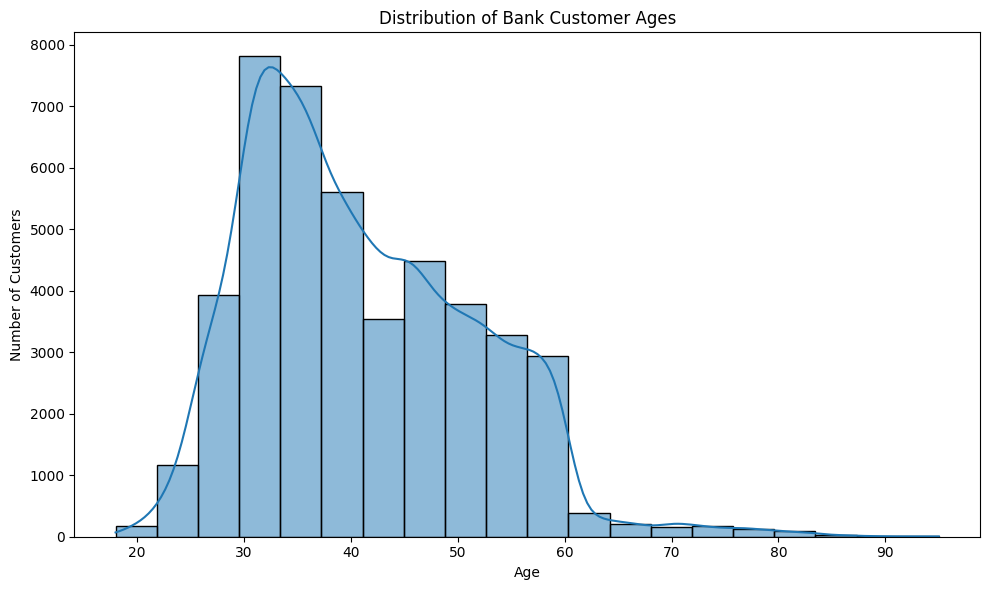

In [9]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='age', bins=20, kde=True)

plt.title('Distribution of Bank Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()

In [10]:
job_subscription = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

job_subscription = job_subscription.sort_values(
    by='yes',
    ascending=False
)

print(job_subscription.round(2))

y                 no    yes
job                        
student        71.32  28.68
retired        77.21  22.79
unemployed     84.50  15.50
management     86.24  13.76
admin.         87.80  12.20
self-employed  88.16  11.84
unknown        88.19  11.81
technician     88.94  11.06
services       91.12   8.88
housemaid      91.21   8.79
entrepreneur   91.73   8.27
blue-collar    92.73   7.27


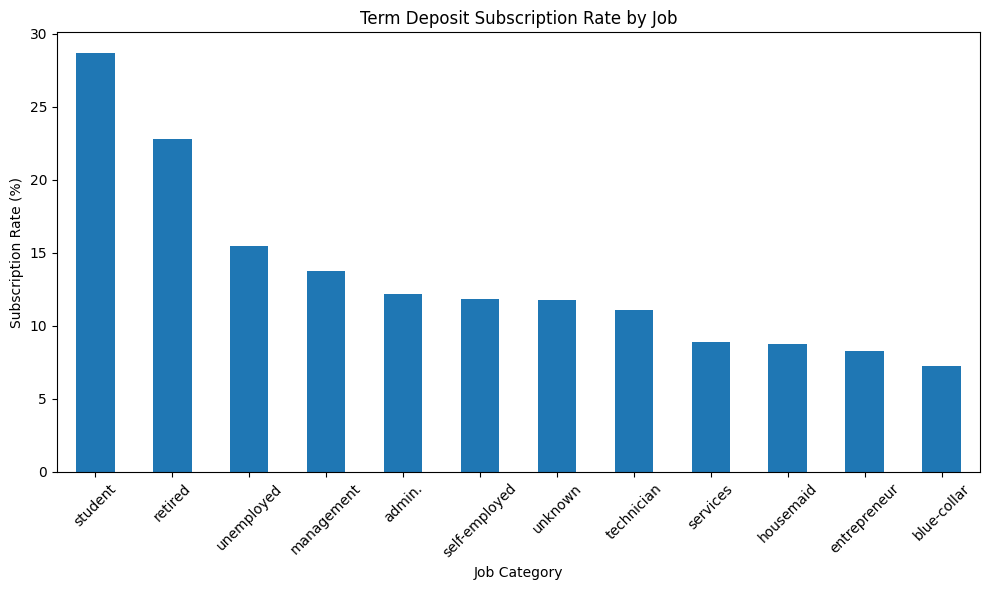

In [11]:
job_subscription['yes'].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Term Deposit Subscription Rate by Job')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

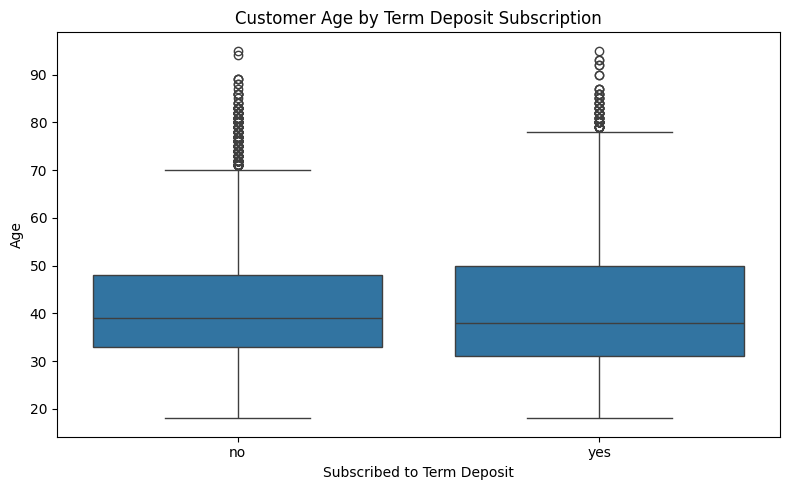

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='y', y='age')

plt.title('Customer Age by Term Deposit Subscription')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Age')

plt.tight_layout()
plt.show()

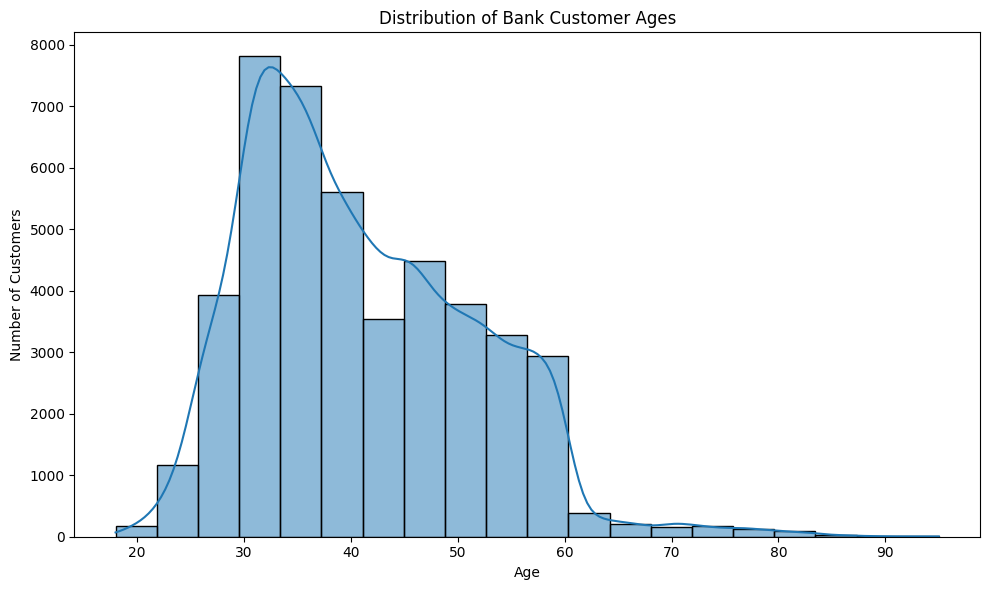

In [13]:
plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='age', bins=20, kde=True)

plt.title('Distribution of Bank Customer Ages')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.tight_layout()

plt.savefig(
    'bank_customer_age_distribution_task2.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [15]:
print("Total customers:", len(df))

print("Average customer age:", round(df['age'].mean(), 2))

print("Youngest customer age:", df['age'].min())

print("Oldest customer age:", df['age'].max())

print("\nSubscription counts:")
print(df['y'].value_counts())

print("\nMissing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())

Total customers: 45211
Average customer age: 40.94
Youngest customer age: 18
Oldest customer age: 95

Subscription counts:
y
no     39922
yes     5289
Name: count, dtype: int64

Missing values: 0
Duplicate rows: 0
